In [3]:
import os
import subprocess

if not os.path.exists("/content/YantraDrishti"):
    subprocess.run(["git", "clone", "https://github.com/MansiTechie/YantraDrishti.git", "/content/YantraDrishti"], check=True)

os.chdir("/content/YantraDrishti")
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "switch", "-c", "feature/ml-day3-rul-baseline", "origin/develop"], check=True)

print("Current branch:", subprocess.check_output(["git", "branch", "--show-current"], text=True))
print("Project path:", os.getcwd())

Current branch: feature/ml-day3-rul-baseline

Project path: /content/YantraDrishti


In [4]:

from pathlib import Path
import os
import json
import pandas as pd
import numpy as np

def find_project_root():
    candidates = [Path.cwd().resolve()]

    # Google Colab repository location
    colab_repo = Path("/content/YantraDrishti")
    if colab_repo.exists():
        candidates.append(colab_repo.resolve())

    for current in candidates:
        for folder in [current, *current.parents]:
            if (
                (folder / "datasets" / "processed" / "train_prepared.csv").is_file()
                and (folder / "ml" / "notebooks").is_dir()
            ):
                return folder

    raise FileNotFoundError("YantraDrishti project root not found.")

ROOT = find_project_root()
DATA_DIR = ROOT / "datasets" / "processed"

print("Project root:", ROOT)
print("Data directory:", DATA_DIR)

# Load only training and validation datasets
train_df = pd.read_csv(DATA_DIR / "train_prepared.csv")
val_df = pd.read_csv(DATA_DIR / "validation_prepared.csv")

# Load existing Day 2 manifest
with open(DATA_DIR / "split_manifest.json") as f:
    manifest = json.load(f)

print("\nTraining shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Expected features:", len(manifest["feature_columns"]))


Project root: /content/YantraDrishti
Data directory: /content/YantraDrishti/datasets/processed

Training shape: (16561, 48)
Validation shape: (4070, 48)
Expected features: 46


In [5]:
features = manifest["feature_columns"]

X_train = train_df[features].copy()
y_train = train_df["RUL"].copy()

X_val = val_df[features].copy()
y_val = val_df["RUL"].copy()

assert len(features) == 46
assert "unit_number" not in features
assert "RUL" not in features
assert X_train.shape == (16561, 46)
assert X_val.shape == (4070, 46)
assert y_train.notna().all()
assert y_val.notna().all()
assert X_train.notna().all().all()
assert X_val.notna().all().all()

assert set(train_df["unit_number"]).isdisjoint(set(val_df["unit_number"]))

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("Missing values:", X_train.isna().sum().sum() + X_val.isna().sum().sum())
print("Engine overlap:", len(set(train_df["unit_number"]) & set(val_df["unit_number"])))
print("All validations passed!")

X_train: (16561, 46)
y_train: (16561,)
X_val: (4070, 46)
y_val: (4070,)
Missing values: 0
Engine overlap: 0
All validations passed!


In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_val)
rf_pred = rf_model.predict(X_val)

print("Dummy MAE:", mean_absolute_error(y_val, dummy_pred))
print("Dummy RMSE:", np.sqrt(mean_squared_error(y_val, dummy_pred)))

print("\nRandom Forest MAE:", mean_absolute_error(y_val, rf_pred))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_val, rf_pred)))

Dummy MAE: 55.363284140368854
Dummy RMSE: 65.71544508456086

Random Forest MAE: 23.474377113397434
Random Forest RMSE: 30.87114635145243


In [7]:
def nasa_score(actual, predicted):
    d = predicted - actual
    scores = np.where(
        d < 0,
        np.exp(-d / 13) - 1,
        np.exp(d / 10) - 1
    )
    return np.sum(scores)

dummy_nasa = nasa_score(y_val.to_numpy(), dummy_pred)
rf_nasa = nasa_score(y_val.to_numpy(), rf_pred)

print("Dummy NASA Score:", dummy_nasa)
print("Random Forest NASA Score:", rf_nasa)

print("\nNASA Score Verification:")
print("Underestimation:", nasa_score(np.array([100]), np.array([90])))
print("Overestimation:", nasa_score(np.array([100]), np.array([110])))

Dummy NASA Score: 19351068.755096164
Random Forest NASA Score: 253571.04539612017

NASA Score Verification:
Underestimation: 1.1581055339484458
Overestimation: 1.718281828459045


In [8]:
comparison = pd.DataFrame({
    "Model": ["Dummy Regressor", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_val, dummy_pred),
        mean_absolute_error(y_val, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, dummy_pred)),
        np.sqrt(mean_squared_error(y_val, rf_pred))
    ],
    "NASA Score": [dummy_nasa, rf_nasa]
})

print(comparison.round(3).to_string(index=False))

          Model    MAE   RMSE   NASA Score
Dummy Regressor 55.363 65.715 19351068.755
  Random Forest 23.474 30.871   253571.045


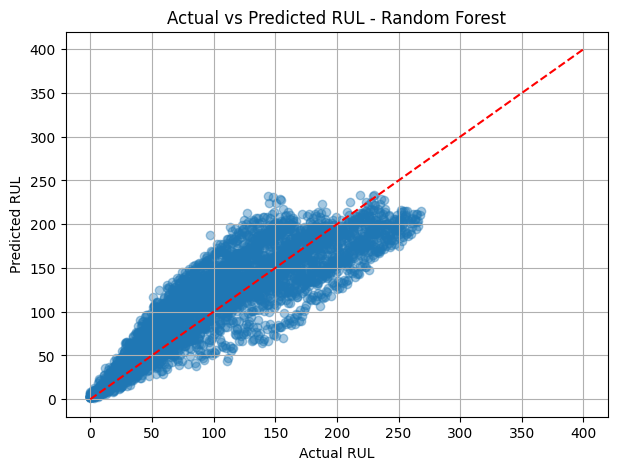

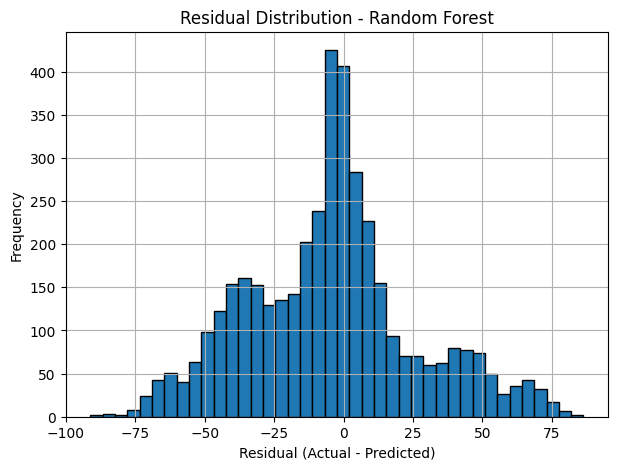

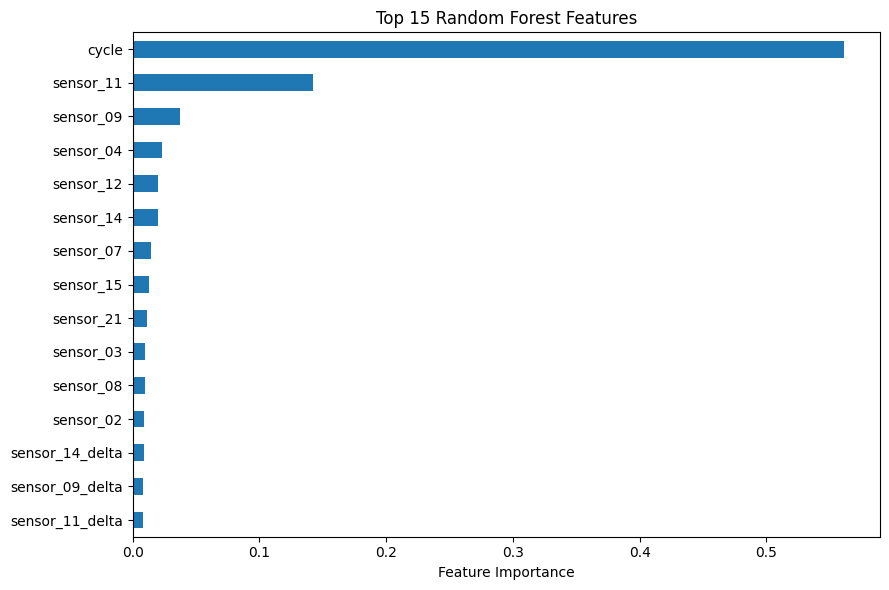

In [9]:
import matplotlib.pyplot as plt

residuals = y_val.to_numpy() - rf_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_val, rf_pred, alpha=0.4)
plt.plot([0, 400], [0, 400], "r--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Random Forest")
plt.grid()
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Random Forest")
plt.grid()
plt.show()

importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")
plt.xlabel("Feature Importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.show()

In [10]:
import joblib

MODEL_DIR = ROOT / "ml" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": rf_model,
    "features": features,
    "model_name": "RandomForestRegressor",
    "random_state": 42
}

model_path = MODEL_DIR / "rul_baseline.joblib"

joblib.dump(model_artifact, model_path)

loaded_artifact = joblib.load(model_path)

assert loaded_artifact["features"] == features
assert loaded_artifact["model"].predict(X_val).shape == y_val.shape

print("Model saved:", model_path)
print("File size:", round(model_path.stat().st_size / 1024, 2), "KB")
print("Model reload verification passed!")

Model saved: /content/YantraDrishti/ml/models/rul_baseline.joblib
File size: 51177.18 KB
Model reload verification passed!


In [11]:
from datetime import datetime, timezone

METRICS_DIR = ROOT / "ml" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

metrics = {
    "dataset": "NASA C-MAPSS FD001",
    "model_name": "RandomForestRegressor",
    "parameters": rf_model.get_params(),
    "features": features,
    "train_rows": len(X_train),
    "validation_rows": len(X_val),
    "mae": float(mean_absolute_error(y_val, rf_pred)),
    "rmse": float(np.sqrt(mean_squared_error(y_val, rf_pred))),
    "nasa_score": float(rf_nasa),
    "random_seed": 42,
    "evaluation_timestamp": datetime.now(timezone.utc).isoformat(),
    "limitations": [
        "Evaluated only on the validation split.",
        "Test dataset was not used for training or model selection.",
        "Baseline model; extensive hyperparameter tuning was not performed.",
        "Performance is specific to C-MAPSS FD001."
    ]
}

metrics_path = METRICS_DIR / "day3_rul_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("Metrics saved:", metrics_path)
print("MAE:", metrics["mae"])
print("RMSE:", metrics["rmse"])
print("NASA Score:", metrics["nasa_score"])

Metrics saved: /content/YantraDrishti/ml/metrics/day3_rul_metrics.json
MAE: 23.474377113397434
RMSE: 30.87114635145243
NASA Score: 253571.04539612017


In [12]:
REPORT_DIR = ROOT / "ml" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = f"""# Day 3 — FD001 RUL Regression Baseline

## Objective
Train and evaluate baseline Remaining Useful Life regression models using NASA C-MAPSS FD001 prepared training and validation datasets.

## Dataset
- Dataset: NASA C-MAPSS FD001
- Training rows: {len(X_train)}
- Validation rows: {len(X_val)}
- Features: {len(features)}
- Training engines: {train_df['unit_number'].nunique()}
- Validation engines: {val_df['unit_number'].nunique()}

## Models
1. DummyRegressor(strategy='mean')
2. RandomForestRegressor

### Random Forest Parameters
- n_estimators: 150
- max_depth: 15
- min_samples_split: 5
- min_samples_leaf: 2
- random_state: 42
- n_jobs: -1

## Validation Results

| Model | MAE | RMSE | NASA Score |
|---|---:|---:|---:|
| Dummy Regressor | {mean_absolute_error(y_val, dummy_pred):.3f} | {np.sqrt(mean_squared_error(y_val, dummy_pred)):.3f} | {dummy_nasa:.3f} |
| Random Forest | {metrics['mae']:.3f} | {metrics['rmse']:.3f} | {metrics['nasa_score']:.3f} |

## Evaluation
Random Forest outperformed the Dummy Regressor across all three evaluation metrics.

NASA score penalizes RUL overestimation more heavily than underestimation.

## Data Validation
- No missing feature values.
- No duplicate unit-cycle records.
- No overlap between training and validation engines.
- unit_number excluded from model features.
- RUL excluded from model input features.
- Test dataset was not used for training or model selection.

## Limitations
- Baseline model with limited hyperparameter tuning.
- Evaluation performed only on the validation split.
- Results are specific to FD001 and should not be generalized to other subsets without testing.
- No anomaly detection or SHAP analysis was performed.

## Saved Artifacts
- ml/models/rul_baseline.joblib
- ml/metrics/day3_rul_metrics.json
- ml/reports/day3_rul_baseline.md
"""

report_path = REPORT_DIR / "day3_rul_baseline.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print(report)

Report saved: /content/YantraDrishti/ml/reports/day3_rul_baseline.md
Report size: 1595 bytes
# Day 3 — FD001 RUL Regression Baseline

## Objective
Train and evaluate baseline Remaining Useful Life regression models using NASA C-MAPSS FD001 prepared training and validation datasets.

## Dataset
- Dataset: NASA C-MAPSS FD001
- Training rows: 16561
- Validation rows: 4070
- Features: 46
- Training engines: 80
- Validation engines: 20

## Models
1. DummyRegressor(strategy='mean')
2. RandomForestRegressor

### Random Forest Parameters
- n_estimators: 150
- max_depth: 15
- min_samples_split: 5
- min_samples_leaf: 2
- random_state: 42
- n_jobs: -1

## Validation Results

| Model | MAE | RMSE | NASA Score |
|---|---:|---:|---:|
| Dummy Regressor | 55.363 | 65.715 | 19351068.755 |
| Random Forest | 23.474 | 30.871 | 253571.045 |

## Evaluation
Random Forest outperformed the Dummy Regressor across all three evaluation metrics.

NASA score penalizes RUL overestimation more heavily than underestim

In [13]:
import json
import joblib
import pandas as pd
import numpy as np

model_path = ROOT / "ml/models/rul_baseline.joblib"
metrics_path = ROOT / "ml/metrics/day3_rul_metrics.json"
report_path = ROOT / "ml/reports/day3_rul_baseline.md"

assert model_path.exists()
assert metrics_path.exists()
assert report_path.exists()

saved_model = joblib.load(model_path)

with open(metrics_path) as f:
    saved_metrics = json.load(f)

assert saved_model["features"] == features
assert saved_model["model"].predict(X_val).shape == y_val.shape
assert np.isclose(saved_metrics["mae"], mean_absolute_error(y_val, rf_pred))
assert np.isclose(saved_metrics["rmse"], np.sqrt(mean_squared_error(y_val, rf_pred)))
assert np.isclose(saved_metrics["nasa_score"], rf_nasa)

print("All final validations passed!")
print("\nArtifacts:")
for path in [model_path, metrics_path, report_path]:
    print(path.relative_to(ROOT), round(path.stat().st_size / 1024, 2), "KB")

print("\nValidation metrics:")
print("MAE:", saved_metrics["mae"])
print("RMSE:", saved_metrics["rmse"])
print("NASA Score:", saved_metrics["nasa_score"])

All final validations passed!

Artifacts:
ml/models/rul_baseline.joblib 51177.18 KB
ml/metrics/day3_rul_metrics.json 2.22 KB
ml/reports/day3_rul_baseline.md 1.56 KB

Validation metrics:
MAE: 23.474377113397434
RMSE: 30.87114635145243
NASA Score: 253571.04539612017


In [14]:
import shutil
from pathlib import Path

shutil.make_archive(
    "/content/YantraDrishti_Day3_Artifacts",
    "zip",
    ROOT,
    "ml"
)

from google.colab import files
files.download("/content/YantraDrishti_Day3_Artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>